1. Data Frame moderated

In [ ]:
students <- data.frame(
STUDENT_ID = c("S001", "S002", "S003", "S004", "S005"),
ATTENDANCE = c(95,72,88,79,68),
GRADE = c(90,70,85,77,65),
RISK = c("Low Risk", "High Risk", "Low Risk", "Moderate Risk", "High Risk")
)
students
write.csv(students, "student.csv")

STUDENT_ID,ATTENDANCE,GRADE,RISK
<chr>,<dbl>,<dbl>,<chr>
S001,95,90,Low Risk
S002,72,70,High Risk
S003,88,85,Low Risk
S004,79,77,Moderate Risk
S005,68,65,High Risk


2. Creating Variables

In [ ]:
attendace_rate <- 0.82
average_grade <- 78

attendace_rate
average_grade

3. Basic calculations

In [ ]:
quiz <- 85
laboratory <- 90
project <- 88
exam <- 80

quiz_weight <- 0.20
lab_weight <- 0.25
project_weight <- 0.25
exam_weight <- 0.30

final_grade = (quiz * quiz_weight) + (laboratory * lab_weight) + (project * project_weight) + (exam * exam_weight)

final_grade

[1] 85.5

4. Using comparison operators

In [ ]:
attendance <- 72
grade <- 70

attendance < 75
grade < 75
attendance >= 75
grade >= 75


[1] TRUE

[1] TRUE

[1] FALSE

[1] FALSE

5. using AND and OR

In [ ]:
if (grade < 75 & attendance < 72) {
  print ("at risk")
} else if (grade < 75 | attendance < 72) {
  print("at risk")
}

[1] "at risk"


6. Simple If statement

In [ ]:
grade <- 75
if (grade <75){
  print ("Failed")
}else{
print("Passed")
}

[1] "Passed"


7. multiple conditions

In [ ]:
grade <- 88

if (grade >= 90 && grade <= 100) {
  print("Excellent")
} else if (grade >= 85 && grade <= 89) {
  print("Very Good")
} else if (grade >= 80 && grade <= 84) {
  print("Good")
} else if (grade >= 75 && grade <= 79) {
  print("Passed")
} else if (grade < 75) {
  print("Failed")
} else {
  print("Invalid Grade")
}

[1] "Very Good"


8. creating a function

In [ ]:
classify_grade <- function(grade) {
  if (grade >= 90 && grade <= 100) {
    return("Excellent")
  } else if (grade >= 85 && grade <= 89) {
    return("Very Good")
  } else if (grade >= 80 && grade <= 84) {
    return("Good")
  } else if (grade >= 75 && grade <= 79) {
    return("Passed")
  } else if (grade < 75) {
    return("Failed")
  } else {
    return("Invalid Grade")
  }
}

student_grade <- 88
performance <- classify_grade(student_grade)
print(paste("student grade", student_grade, "classified as:", performance))

student_grade_2 <- 60
performance_2 <- classify_grade(student_grade_2)
print(paste("student grade", student_grade_2, "classified as:", performance_2))

[1] "student grade 88 classified as: Very Good"
[1] "student grade 60 classified as: Failed"


9. creating data frame

In [ ]:
students <- data.frame(
STUDENT_ID = c("S001", "S002", "S003", "S004", "S005"),
ATTENDANCE = c(95,72,88,79,68),
GRADE = c(90,70,85,77,65)
)
students
write.csv(students, "student.csv")

STUDENT_ID,ATTENDANCE,GRADE
<chr>,<dbl>,<dbl>
S001,95,90
S002,72,70
S003,88,85
S004,79,77
S005,68,65


10. adding a classification column

In [ ]:
students$Performance <- rep(NA_character_, nrow(students))
students$Performance[students$GRADE >= 80] <- "Good"
students$Performance[students$GRADE >= 75 & students$GRADE < 80] <- "passed"
students$Performance[students$GRADE < 75] <- "failed"
students

STUDENT_ID,ATTENDANCE,GRADE,Performance
<chr>,<dbl>,<dbl>,<chr>
S001,95,90,Good
S002,72,70,failed
S003,88,85,Good
S004,79,77,passed
S005,68,65,failed


11. apply the rule to multiple students

In [ ]:
students$Risk <- mapply(
  student_risk,
  students$ATTENDANCE,
  students$GRADE
)
students

STUDENT_ID,ATTENDANCE,GRADE,Performance,Risk
<chr>,<dbl>,<dbl>,<chr>,<chr>
S001,95,90,Good,Low Risk
S002,72,70,failed,High Risk
S003,88,85,Good,Low Risk
S004,79,77,passed,Low Risk
S005,68,65,failed,High Risk


12. creating simple rule based system

In [ ]:
student_risk <- function(attendance, grade) {
  if (attendance < 75 && grade < 75) {
    return("High Risk")
  } else if (attendance < 75 || grade < 75) {
    return("Moderate Risk")
  } else {
    return("Low Risk")
  }
}

add more rules

In [ ]:
classify_risk_improved <- function(attendance, grade) {
  if (attendance < 75 && grade < 75) {
    return("HIGH RISK")
  } else if (attendance >= 85 && grade >= 80) {
    return("LOW RISK")
  } else {
    return("MODERATE RISK")
  }
}

students$Risk <- mapply(
  classify_risk_improved,
  students$ATTENDANCE,
  students$GRADE
)
students

STUDENT_ID,ATTENDANCE,GRADE,Performance,Risk
<chr>,<dbl>,<dbl>,<chr>,<chr>
S001,95,90,Good,LOW RISK
S002,72,70,failed,HIGH RISK
S003,88,85,Good,LOW RISK
S004,79,77,passed,MODERATE RISK
S005,68,65,failed,HIGH RISK


13. count the results

In [ ]:
table(students$Risk)


    HIGH RISK      LOW RISK MODERATE RISK 
            2             2             1 

1. students on high risk? 2
2. moderate risk? 1
3. low risk? 2
4. largest number of students? high and low risk







14. create a visualization

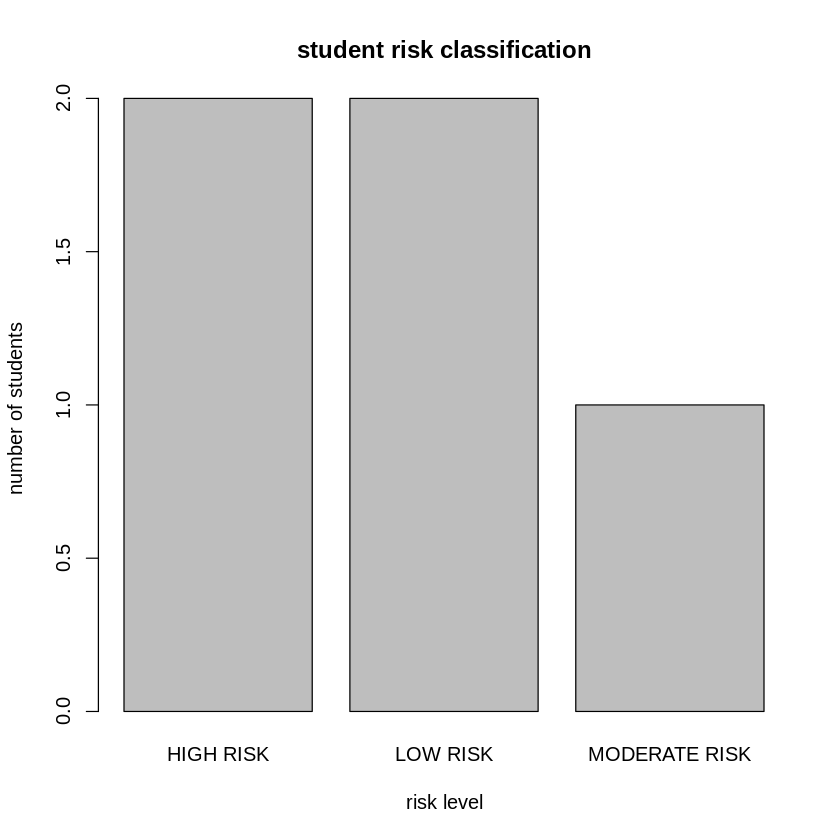

In [ ]:
risk_counts <- table(students$Risk)

barplot(
  risk_counts,
  main = "student risk classification",
  xlab = "risk level",
  ylab = "number of students"
)



1. grap shows? student risk classification determined by graph showing low and high risk being on the same level or teh highest
2. category with most students? high and low
3. what action should the univ take? talk with the students that are on the high and low risk besides that implement certent rules not only dropping their grades but do a different approach like encouraging them so they wont miss attendance and try their best to cooperate and do their assignments and review so grades wont drop, asses good activities for the kids and help them discover their potentials.



15. add a reco

In [ ]:
generate_recommendation <- function(risk_level) {
  if (risk_level == "HIGH RISK") {
    return("Immediate academic intervention: personalized tutoring, counseling, and parent-teacher conference.")
  } else if (risk_level == "MODERATE RISK") {
    return("Academic support: identify specific challenges, offer extra help sessions, and monitor progress closely.")
  } else if (risk_level == "LOW RISK") {
    return("Continued engagement: encourage participation in advanced programs and provide resources for further growth.")
  } else {
    return("No specific recommendation.")
  }
}

students$Recommendation <- mapply(generate_recommendation, students$Risk)
students

STUDENT_ID,ATTENDANCE,GRADE,Performance,Risk,Recommendation
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
S001,95,90,Good,LOW RISK,Continued engagement: encourage participation in advanced programs and provide resources for further growth.
S002,72,70,failed,HIGH RISK,"Immediate academic intervention: personalized tutoring, counseling, and parent-teacher conference."
S003,88,85,Good,LOW RISK,Continued engagement: encourage participation in advanced programs and provide resources for further growth.
S004,79,77,passed,MODERATE RISK,"Academic support: identify specific challenges, offer extra help sessions, and monitor progress closely."
S005,68,65,failed,HIGH RISK,"Immediate academic intervention: personalized tutoring, counseling, and parent-teacher conference."


16. mini krr system

In [ ]:

get_risk_reasoning <- function(attendance, grade) {
  if (attendance < 75 && grade < 75) {
    return("Reasoning: Both attendance and grade are below the critical thresholds of 75%.")
  } else if (attendance >= 85 && grade >= 80) {
    return("Reasoning: Both attendance and grade are above the satisfactory thresholds of 85% and 80% respectively.")
  } else {
    return("Reasoning: The student's attendance and/or grade do not meet the criteria for HIGH RISK or LOW RISK, placing them in the MODERATE RISK category.")
  }
}
process_student_data <- function(student_id, attendance, grade) {
  # 1. Input
  print(paste("\n--- Processing Student:", student_id, "---"))
  print(paste("Attendance:", attendance, "%"))
  print(paste("Grade:", grade))

  # 2. Classification
  risk_level <- classify_risk_improved(attendance, grade)
  print(paste("Risk Level:", risk_level))

  # 3. Reasoning
  reasoning <- get_risk_reasoning(attendance, grade)
  print(reasoning)

  # 4. Recommendation
  recommendation <- generate_recommendation(risk_level)
  print(paste("Recommendation:", recommendation))
}

#student S002
process_student_data("S002", 72, 70)


[1] "\n--- Processing Student: S002 ---"
[1] "Attendance: 72 %"
[1] "Grade: 70"
[1] "Risk Level: HIGH RISK"
[1] "Reasoning: Both attendance and grade are below the critical thresholds of 75%."
[1] "Recommendation: Immediate academic intervention: personalized tutoring, counseling, and parent-teacher conference."
